# Diabetes Prediction using Machine Learning
### Assignment 1: End-to-End Classification Pipeline (Logistic Regression)

**Dataset:** `diabetes.csv` (Pima Indians Diabetes Dataset, 768 patients, 8 medical predictors)
**Goal:** Predict whether a patient is likely to have diabetes (`Outcome`: 0 = No, 1 = Yes)
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

---
**Contents**

| Part | Topic |
|---|---|
| 1 | Data Preparation (load, explore, features/target, split, preprocessing) |
| 2 | Machine Learning Model Building |
| 3 | Model Training and Evaluation |
| 4 | Model Performance Analysis and Conclusions |

---
# Part 1: Data Preparation

## 1.1 Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_auc_score, roc_curve)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print("Libraries imported successfully")

Libraries imported successfully


## 1.2 Load the dataset using Pandas

In [2]:
df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 1.3 Explore the dataset

### (a) Shape, (b) column names, (c) data types, (d) missing values

In [3]:
print("Shape of the dataset (rows, columns):", df.shape)
print("\nColumn names:")
print(list(df.columns))
print("\nData types:")
print(df.dtypes)
print("\nMissing values (NaN) per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Shape of the dataset (rows, columns): (768, 9)

Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Missing values (NaN) per column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Duplicate rows: 0


**Observations**
- The dataset has **768 rows and 9 columns** (8 input features + 1 target).
- All columns are numeric (`int64` / `float64`), so **no categorical encoding is needed** for the raw data.
- There are **no `NaN` values** and **no duplicate rows**.

### (e) Basic statistical summary

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


Looking at the `min` column reveals a hidden problem: **Glucose, BloodPressure, SkinThickness, Insulin and BMI have a minimum of 0**, which is impossible for a living patient. Let's quantify this.

In [5]:
# In this dataset, 0 is physiologically impossible for these columns,
# so zeros here actually represent MISSING measurements.
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_summary = pd.DataFrame({
    "zero_count": (df[zero_cols] == 0).sum(),
    "zero_percent": ((df[zero_cols] == 0).mean() * 100).round(2)
})
zero_summary

,zero_count,zero_percent
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43


**Key finding: hidden missing values.** Although `isnull()` reports nothing missing, the value `0` has been used as a placeholder for missing measurements in five columns. `Insulin` (about 49 %) and `SkinThickness` (about 30 %) are affected the most. Treating these zeros as real values would badly distort the model, so they are converted to `NaN` and imputed in the preprocessing stage. (`Pregnancies = 0` is legitimate and is left unchanged.)

### Target variable distribution

Outcome
0    500
1    268
Name: count, dtype: int64

Class percentages:
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64


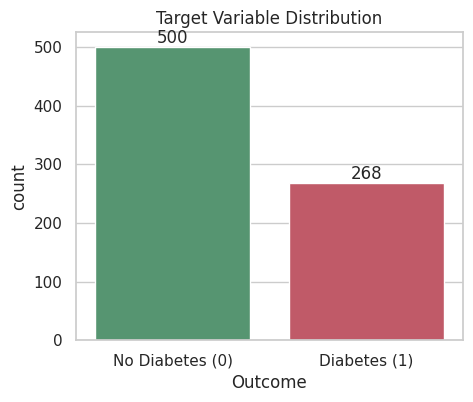

In [6]:
counts = df["Outcome"].value_counts().sort_index()
print(counts)
print("\nClass percentages:")
print((df["Outcome"].value_counts(normalize=True).sort_index() * 100).round(2))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x="Outcome", data=df, ax=ax, palette=["#4C9F70", "#D1495B"])
ax.set_xticklabels(["No Diabetes (0)", "Diabetes (1)"])
ax.set_title("Target Variable Distribution")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.show()

The target is **moderately imbalanced**: about 65 % of patients have no diabetes and 35 % do. Because of this, **accuracy alone can be misleading** (a model that always predicts "No Diabetes" would already score about 65 %), so Precision, Recall and F1 are also reported. A *stratified* split is used to preserve this ratio.

### Feature distributions and relationships

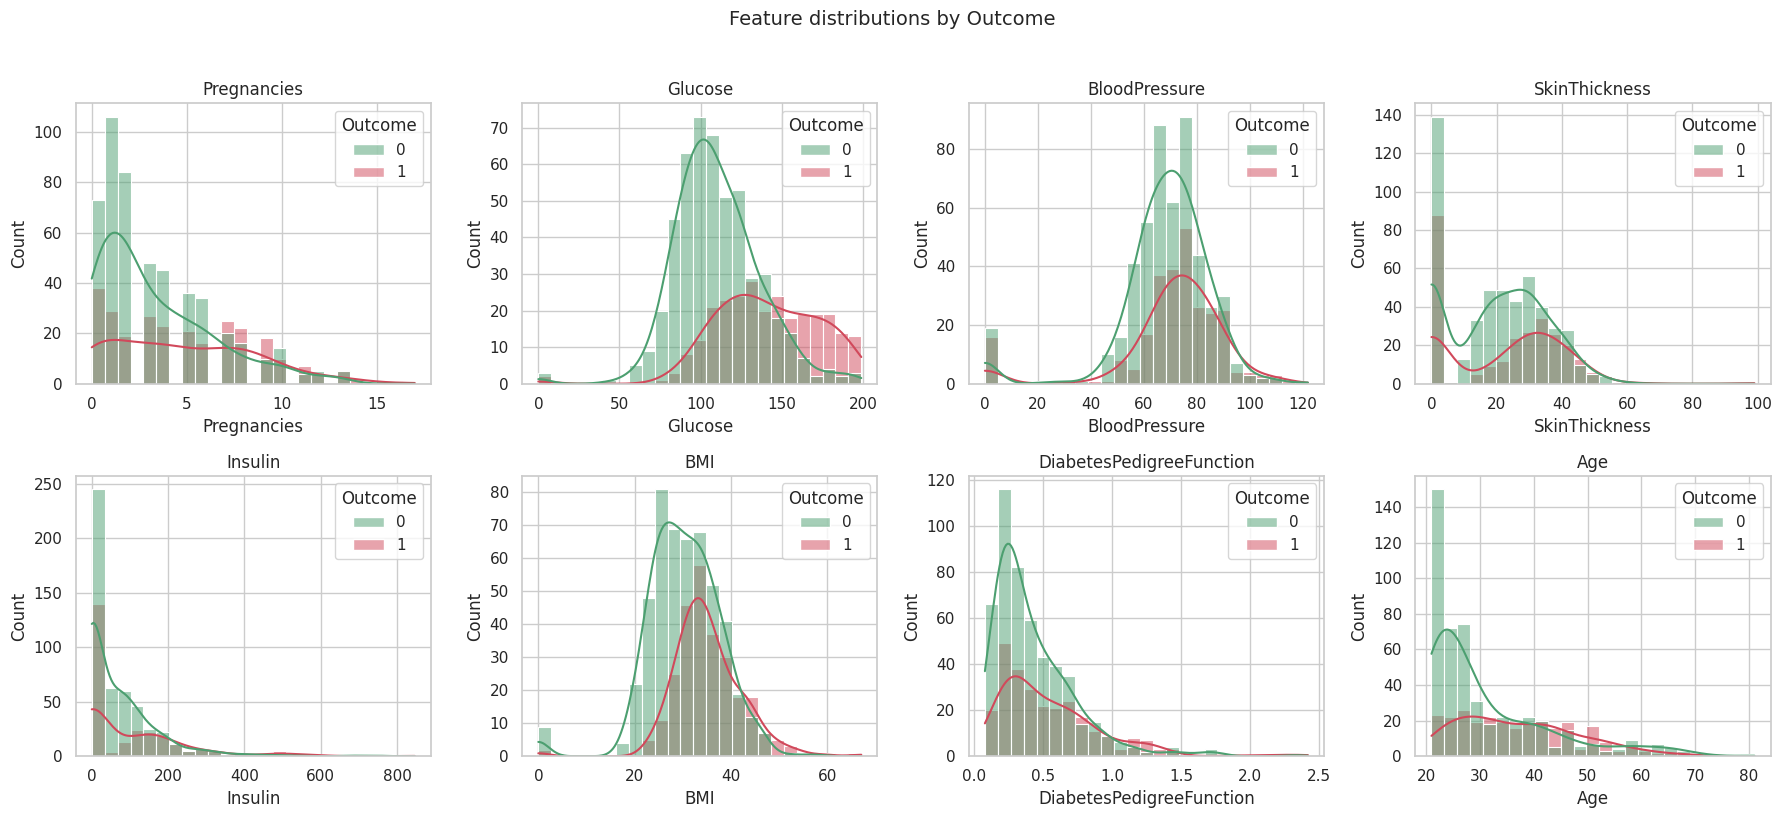

In [7]:
features = df.columns.drop("Outcome")
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(data=df, x=col, hue="Outcome", kde=True, ax=ax, bins=25,
                 palette=["#4C9F70", "#D1495B"])
    ax.set_title(col)
plt.suptitle("Feature distributions by Outcome", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

Correlation of each feature with Outcome:
Glucose                     0.467
BMI                         0.293
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
Insulin                     0.131
SkinThickness               0.075
BloodPressure               0.065
Name: Outcome, dtype: float64


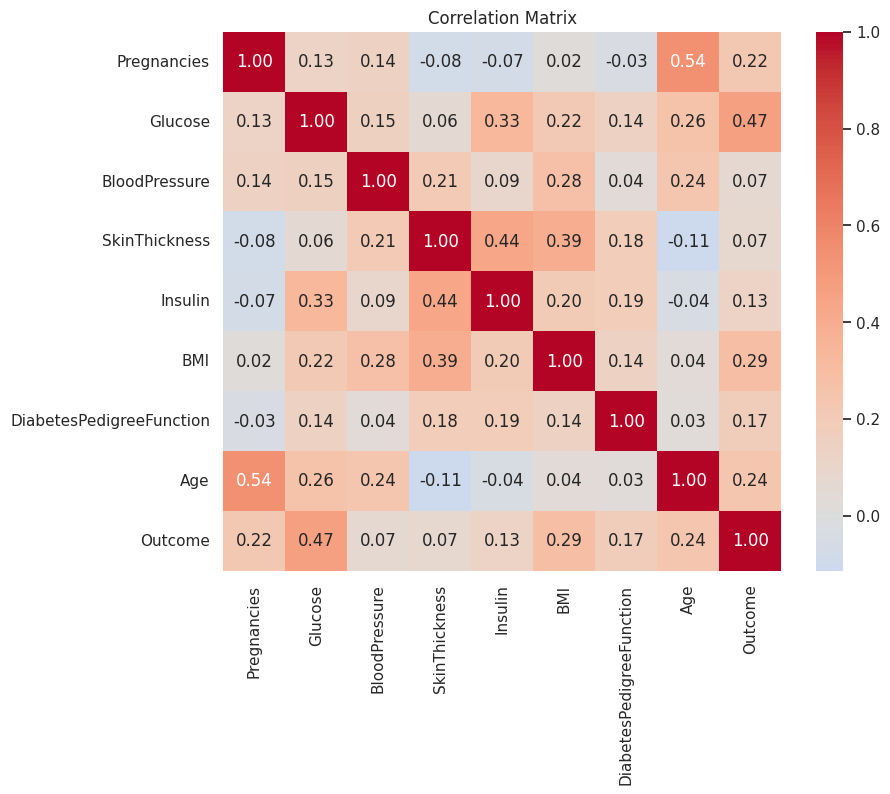

In [8]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.show()

print("Correlation of each feature with Outcome:")
print(df.corr()["Outcome"].drop("Outcome").sort_values(ascending=False).round(3))

- **Glucose** has by far the strongest correlation with `Outcome` (0.47), followed by **BMI** (0.29), **Age** (0.24) and **Pregnancies** (0.22).
- `BloodPressure` and `SkinThickness` are only weakly related to the outcome.
- Correlation between predictors is moderate (e.g. Age vs Pregnancies, Insulin vs SkinThickness), so multicollinearity is not a serious concern for Logistic Regression here.

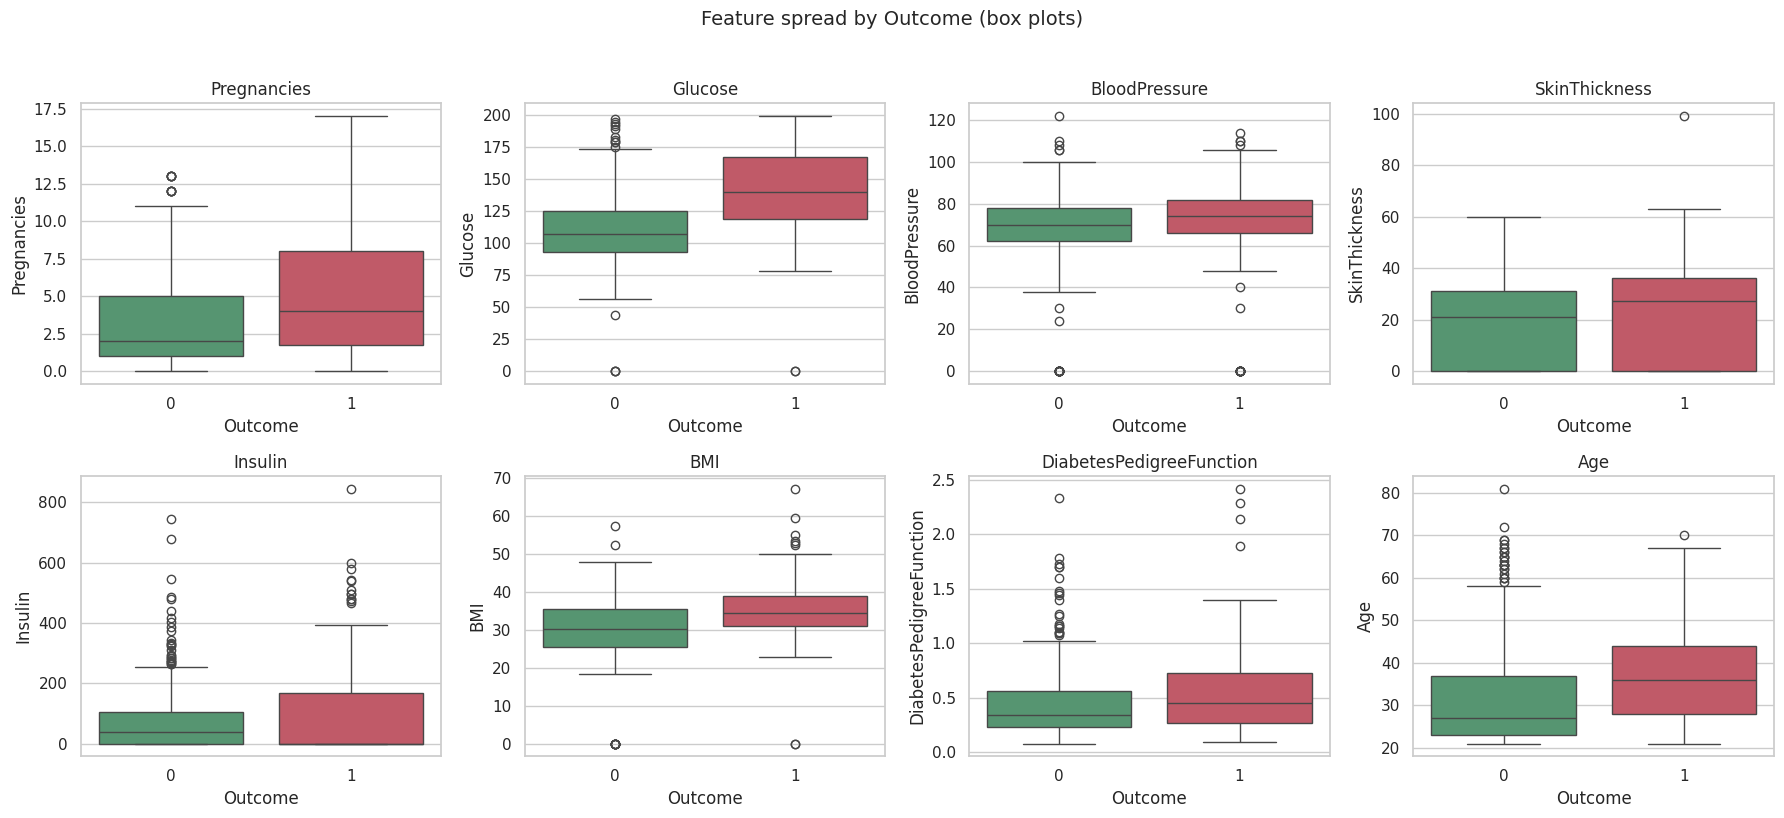

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(data=df, x="Outcome", y=col, ax=ax, palette=["#4C9F70", "#D1495B"])
    ax.set_title(col)
plt.suptitle("Feature spread by Outcome (box plots)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

Patients with diabetes clearly show higher Glucose, BMI and Age on average. Several features also contain outliers (Insulin, SkinThickness, DiabetesPedigreeFunction), which is another reason to use **median** (outlier-robust) imputation instead of the mean.

## 1.4 Description of features and target variable

| Column | Type | Description |
|---|---|---|
| Pregnancies | Feature (int) | Number of times pregnant |
| Glucose | Feature (int) | Plasma glucose concentration |
| BloodPressure | Feature (int) | Diastolic blood pressure (mm Hg) |
| SkinThickness | Feature (int) | Triceps skin fold thickness (mm) |
| Insulin | Feature (int) | Serum insulin level (mu U/ml) |
| BMI | Feature (float) | Body Mass Index |
| DiabetesPedigreeFunction | Feature (float) | Diabetes pedigree score (genetic risk based on family history) |
| Age | Feature (int) | Age in years |
| **Outcome** | **Target (binary)** | **0 = No Diabetes, 1 = Diabetes** |

## 1.5 Preprocessing

### Step A: Handle missing values (invalid zeros → NaN)

In [10]:
# Convert impossible zeros to NaN so they can be imputed properly.
df_clean = df.copy()
df_clean[zero_cols] = df_clean[zero_cols].replace(0, np.nan)
print("Missing values after converting invalid zeros to NaN:")
print(df_clean.isnull().sum())

Missing values after converting invalid zeros to NaN:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


### Step B: Feature engineering
Three simple, medically motivated features are added: a **BMI category** (WHO bands), an **Age group**, and a **Glucose × BMI interaction**. The first two are categorical, which also demonstrates categorical encoding.

In [11]:
# Simple, medically meaningful engineered features
df_fe = df_clean.copy()

# 1) BMI category (WHO bands) -> categorical, later one-hot encoded
df_fe["BMI_Category"] = pd.cut(df_fe["BMI"],
                               bins=[0, 18.5, 25, 30, np.inf],
                               labels=["Underweight", "Normal", "Overweight", "Obese"])

# 2) Age group -> categorical
df_fe["Age_Group"] = pd.cut(df_fe["Age"],
                            bins=[0, 30, 45, 60, np.inf],
                            labels=["<=30", "31-45", "46-60", "60+"])

# 3) Glucose x BMI interaction
df_fe["Glucose_BMI"] = df_fe["Glucose"] * df_fe["BMI"]

print(df_fe[["BMI", "BMI_Category", "Age", "Age_Group", "Glucose_BMI"]].head())
print("\nDiabetes rate (%) by BMI category:")
print((df_fe.groupby("BMI_Category", observed=True)["Outcome"].mean() * 100).round(1))
print("\nDiabetes rate (%) by Age group:")
print((df_fe.groupby("Age_Group", observed=True)["Outcome"].mean() * 100).round(1))

    BMI BMI_Category  Age Age_Group  Glucose_BMI
0  33.6        Obese   50     46-60       4972.8
1  26.6   Overweight   31     31-45       2261.0
2  23.3       Normal   32     31-45       4263.9
3  28.1   Overweight   21      <=30       2500.9
4  43.1        Obese   33     31-45       5904.7

Diabetes rate (%) by BMI category:
BMI_Category
Underweight     0.0
Normal          6.5
Overweight     24.4
Obese          46.2
Name: Outcome, dtype: float64

Diabetes rate (%) by Age group:
Age_Group
<=30     21.6
31-45    51.5
46-60    56.0
60+      25.9
Name: Outcome, dtype: float64


The diabetes rate rises sharply with BMI (0 % → 46 % from underweight to obese) and is highest in the 31–60 age groups, showing these engineered features carry real signal. (Underweight has very few patients, so its 0 % should not be over-interpreted.)

### Step C: Encode categorical variables

In [12]:
# Encode the two categorical features (one-hot, drop first to avoid collinearity)
df_model = pd.get_dummies(df_fe, columns=["BMI_Category", "Age_Group"],
                          drop_first=True, dtype=int)
print("Final modelling dataset shape:", df_model.shape)
print(list(df_model.columns))

Final modelling dataset shape: (768, 16)
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome', 'Glucose_BMI', 'BMI_Category_Normal', 'BMI_Category_Overweight', 'BMI_Category_Obese', 'Age_Group_31-45', 'Age_Group_46-60', 'Age_Group_60+']


## 1.6 Separate features (X) and target (y), then Train-Test Split
We use an **80 % / 20 % split**, `stratify=y` (keeps the class ratio equal) and `random_state=42` (reproducible results).

In [13]:
X = df_model.drop("Outcome", axis=1)
y = df_model["Outcome"]
print("X (features) shape:", X.shape)
print("y (target) shape  :", y.shape)

# 80/20 split, stratified to keep the class ratio identical in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

print("\nTraining set :", X_train.shape, "->", len(X_train), "samples")
print("Testing set  :", X_test.shape, "->", len(X_test), "samples")
print("\nDiabetes rate - train: {:.2%} | test: {:.2%}".format(y_train.mean(), y_test.mean()))

X (features) shape: (768, 15)
y (target) shape  : (768,)

Training set : (614, 15) -> 614 samples
Testing set  : (154, 15) -> 154 samples

Diabetes rate - train: 34.85% | test: 35.06%


### Step D: Impute missing values and scale features
- **Imputation:** median (robust to outliers).
- **Scaling:** `StandardScaler` (mean 0, std 1). Logistic Regression is trained with a gradient-based/regularised solver, so features on very different scales (e.g. Insulin up to 846 vs DiabetesPedigreeFunction below 2.5) would hurt convergence and make coefficients incomparable.
- To **avoid data leakage**, the medians and scaling parameters are learned from the **training set only** and then applied to the test set.

In [14]:
# Median imputation + standard scaling, fitted ONLY on training data (no data leakage)
preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_train_scaled = preprocessor.fit_transform(X_train)   # learn medians/means from train only
X_test_scaled = preprocessor.transform(X_test)         # apply the same transformation to test

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index)

print("Missing values remaining in train:", int(X_train_scaled.isnull().sum().sum()))
print("Missing values remaining in test :", int(X_test_scaled.isnull().sum().sum()))
print("\nScaled training features (mean ~0, std ~1):")
X_train_scaled.describe().loc[["mean", "std"]].round(2)

Missing values remaining in train: 0
Missing values remaining in test : 0

Scaled training features (mean ~0, std ~1):


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Glucose_BMI,BMI_Category_Normal,BMI_Category_Overweight,BMI_Category_Obese,Age_Group_31-45,Age_Group_46-60,Age_Group_60+
mean,-0.0,-0.0,0.0,-0.0,-0.0,0.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## Part 1 Deliverables: Summary

| Item | Result |
|---|---|
| Dataset shape | 768 rows × 9 columns |
| Features | 8 original (+ 7 engineered/encoded = 15 model inputs) |
| Target | `Outcome` (0 = 500 patients, 1 = 268 patients) |
| Missing values | None as `NaN`, but 0s in 5 columns were invalid → converted to NaN and median-imputed |
| Categorical encoding | One-hot encoding for engineered `BMI_Category` and `Age_Group` |
| Scaling | `StandardScaler` (fit on train only) |
| **Training set size** | **614 samples (80 %)** |
| **Testing set size** | **154 samples (20 %)** |

---
# Part 2: Machine Learning Model Building

## 2.1 Libraries
All required libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`, and Scikit-learn's `LogisticRegression`, `train_test_split`, `SimpleImputer`, `StandardScaler`, `Pipeline` and `metrics`) were imported in Part 1.

## 2.2 Selected algorithm: Logistic Regression

Logistic Regression models the probability that a patient has diabetes using the sigmoid function:

$$P(\text{diabetes}=1 \mid x) = \frac{1}{1 + e^{-(b_0 + b_1 x_1 + \dots + b_n x_n)}}$$

A patient is classified as diabetic if this probability is ≥ 0.5 (the threshold can be tuned).

## 2.3 Why Logistic Regression is suitable for this problem

1. **Binary classification:** the target has exactly two classes (diabetes / no diabetes), which is what Logistic Regression is designed for.
2. **Probabilistic output:** it gives a risk probability, not just a label, which is valuable in healthcare for screening and prioritising patients.
3. **Interpretability:** coefficients convert into odds ratios, so we can explain *which* factors raise risk. This transparency is often required in medical settings.
4. **Works well on small, tabular data:** with only 768 rows, complex models (deep networks, large ensembles) are prone to overfitting, while a regularised linear model is stable.
5. **Fast and simple baseline:** trains instantly, has few hyperparameters, and gives a strong benchmark. The EDA showed roughly monotonic relationships (higher glucose/BMI/age → higher diabetes rate), which suits a linear decision boundary in the log-odds.
6. **Built-in regularisation (L2):** helps control overfitting and handles the moderately correlated features.

**Limitations:** it assumes a linear relationship between features and log-odds and cannot capture complex interactions automatically (this is why a Glucose × BMI term was engineered).

## 2.4 Model implemented
`sklearn.linear_model.LogisticRegression(max_iter=1000, random_state=42)` trained on the preprocessed, standardised training data.

---
# Part 3: Model Training

## 3.1 Fit the model on the training dataset

In [15]:
model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
model.fit(X_train_scaled, y_train)
print("Model trained successfully")
print(model)
print("\nIntercept:", model.intercept_.round(4))
print("Number of iterations to converge:", model.n_iter_)

Model trained successfully
LogisticRegression(max_iter=1000, random_state=42)

Intercept: [-0.9427]
Number of iterations to converge: [20]


## 3.2 Predictions on the training dataset and training accuracy

In [16]:
y_train_pred = model.predict(X_train_scaled)
train_acc = accuracy_score(y_train, y_train_pred)
print(f"Training Accuracy: {train_acc:.4f} ({train_acc:.2%})")

Training Accuracy: 0.7883 (78.83%)


## 3.3 Evaluation on the testing dataset

Predictions are generated on the **unseen 154-patient test set**, and accuracy, precision, recall and F1-score are computed.

In [17]:
y_test_pred = model.predict(X_test_scaled)
y_test_proba = model.predict_proba(X_test_scaled)[:, 1]

test_acc = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)
auc = roc_auc_score(y_test, y_test_proba)

print(f"Test Accuracy : {test_acc:.4f} ({test_acc:.2%})")
print(f"Precision     : {precision:.4f}")
print(f"Recall        : {recall:.4f}")
print(f"F1-Score      : {f1:.4f}")
print(f"ROC-AUC       : {auc:.4f}")
print("\nFull classification report:")
print(classification_report(y_test, y_test_pred, target_names=["No Diabetes", "Diabetes"]))

Test Accuracy : 0.7338 (73.38%)
Precision     : 0.6444
Recall        : 0.5370
F1-Score      : 0.5859
ROC-AUC       : 0.8407

Full classification report:
              precision    recall  f1-score   support

 No Diabetes       0.77      0.84      0.80       100
    Diabetes       0.64      0.54      0.59        54

    accuracy                           0.73       154
   macro avg       0.71      0.69      0.69       154
weighted avg       0.73      0.73      0.73       154


**Metric definitions (positive class = Diabetes)**
- **Accuracy:** share of all predictions that are correct.
- **Precision:** of the patients predicted diabetic, how many truly are (penalises false alarms).
- **Recall (sensitivity):** of the truly diabetic patients, how many were found (penalises missed cases).
- **F1-score:** harmonic mean of precision and recall.

### Confusion Matrix

Confusion Matrix:
 [[84 16]
 [25 29]]

True Negatives  (TN): 84
False Positives (FP): 16
False Negatives (FN): 25
True Positives  (TP): 29


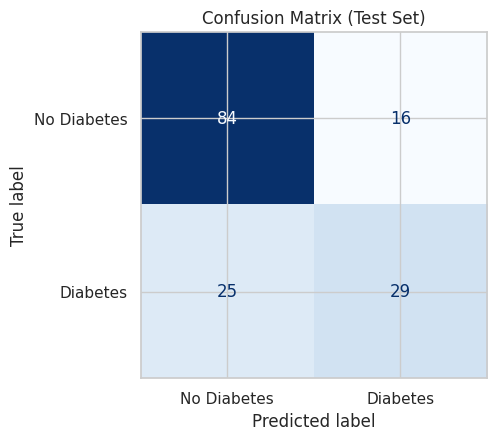

In [18]:
cm = confusion_matrix(y_test, y_test_pred)
tn, fp, fn, tp = cm.ravel()
print("Confusion Matrix:\n", cm)
print(f"\nTrue Negatives  (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives  (TP): {tp}")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["No Diabetes", "Diabetes"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix (Test Set)")
plt.show()

**Reading the matrix** (rows = actual, columns = predicted):
- **84 TN:** non-diabetic patients correctly identified.
- **29 TP:** diabetic patients correctly identified.
- **16 FP:** healthy patients flagged as diabetic (false alarms).
- **25 FN:** diabetic patients the model missed. This is the most costly error type in a medical screening context.

## 3.4 Comparison of training vs testing performance

          Accuracy  Precision  Recall  F1-Score
Dataset                                        
Training    0.7883     0.7471  0.5935    0.6615
Testing     0.7338     0.6444  0.5370    0.5859

Accuracy gap (train - test): +0.0545


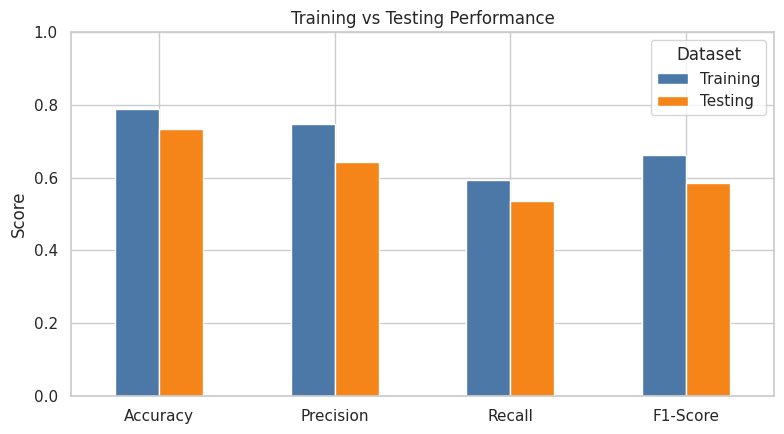

In [19]:
comparison = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Accuracy": [train_acc, test_acc],
    "Precision": [precision_score(y_train, y_train_pred), precision],
    "Recall": [recall_score(y_train, y_train_pred), recall],
    "F1-Score": [f1_score(y_train, y_train_pred), f1],
}).set_index("Dataset").round(4)
print(comparison)
print(f"\nAccuracy gap (train - test): {train_acc - test_acc:+.4f}")

ax = comparison.T.plot(kind="bar", figsize=(8, 4.5), color=["#4C78A8", "#F58518"])
ax.set_ylim(0, 1)
ax.set_title("Training vs Testing Performance")
ax.set_ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretation**
- Accuracy drops from **78.8 % (train)** to **73.4 % (test)**, a gap of about 5.5 percentage points. This is a **mild amount of overfitting**, which is expected on a dataset this small, but it is not severe: the model is not memorising the training data.
- Precision, recall and F1 are all lower on the test set, and the 154-sample test set (only 54 diabetic patients) makes these numbers noisy. A single patient changes recall by about 1.9 percentage points.
- To check how much the specific split matters, 5-fold cross-validation is used below.

In [20]:
# Is the single 80/20 split result reliable? Check with 5-fold stratified CV
# (the pipeline re-fits imputer/scaler inside each fold -> no leakage).
full_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(full_pipe, X, y, cv=cv, scoring="accuracy")
print("5-fold CV accuracy per fold:", cv_scores.round(4))
print(f"Mean CV accuracy: {cv_scores.mean():.4f}  (+/- {cv_scores.std():.4f})")

5-fold CV accuracy per fold: [0.7662 0.7922 0.8052 0.732  0.7516]
Mean CV accuracy: 0.7695  (+/- 0.0265)


Cross-validated accuracy averages **about 77 %** (range 73–81 % across folds). So the 73.4 % test score is at the lower end of what the model typically achieves, mostly because of the luck of the split. A realistic expectation for this model is **roughly 73–77 % accuracy**.

## 3.5 Brief interpretation of the model results

The model correctly classifies about three out of four patients and is clearly better than guessing, but it is noticeably **better at identifying healthy patients (recall for class 0 ≈ 84 %) than diabetic ones (recall for class 1 ≈ 54 %)**. Almost half of the diabetic patients in the test set were missed at the default 0.5 threshold.

---
# Part 4: Model Performance Analysis

## 4.1 Comparison against a naive baseline

In [21]:
# Baseline: always predicting the majority class ("No Diabetes")
baseline_acc = (y_test == 0).mean()
print(f"Majority-class baseline accuracy: {baseline_acc:.4f}")
print(f"Model test accuracy             : {test_acc:.4f}")
print(f"Improvement over baseline       : {test_acc - baseline_acc:+.4f}")

Majority-class baseline accuracy: 0.6494
Model test accuracy             : 0.7338
Improvement over baseline       : +0.0844


The model beats the "always predict No Diabetes" baseline (64.9 %) by about 8.4 percentage points, so it has learned real, useful patterns. Notably, the baseline has **0 % recall** for diabetes, whereas the model finds 54 % of cases.

## 4.2 ROC curve

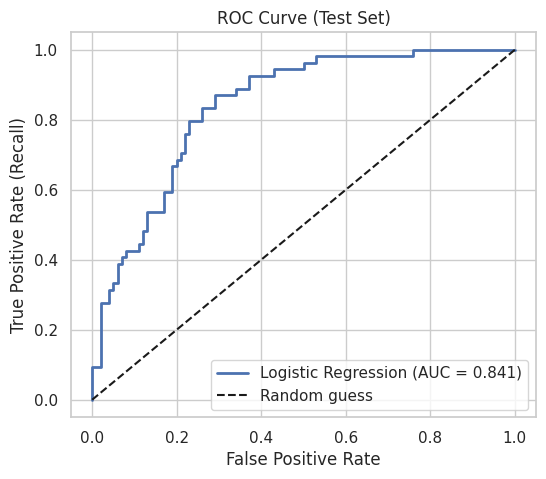

In [22]:
fpr, tpr, _ = roc_curve(y_test, y_test_proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})", lw=2)
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve (Test Set)")
plt.legend(loc="lower right")
plt.show()

The **ROC-AUC of about 0.84** shows good ability to separate diabetic from non-diabetic patients across thresholds (0.5 would be random, 1.0 perfect). This is notably stronger than the accuracy figure suggests, which indicates that the weak recall is largely a **threshold problem, not a ranking problem**: the model ranks patients well, but the default 0.5 cut-off is too conservative for the minority class.

## 4.3 Which features drive the prediction?

                     Feature  Coefficient  Odds_Ratio
0                    Glucose        1.237       3.446
1                        BMI        0.475       1.608
2            Age_Group_31-45        0.324       1.383
3            Age_Group_46-60        0.302       1.352
4   DiabetesPedigreeFunction        0.201       1.223
5                Pregnancies        0.183       1.201
6                        Age        0.121       1.128
7         BMI_Category_Obese        0.088       1.092
8              SkinThickness        0.024       1.024
9                Glucose_BMI       -0.030       0.971
10   BMI_Category_Overweight       -0.039       0.961
11             BloodPressure       -0.066       0.936
12                   Insulin       -0.106       0.900
13             Age_Group_60+       -0.165       0.848
14       BMI_Category_Normal       -0.374       0.688


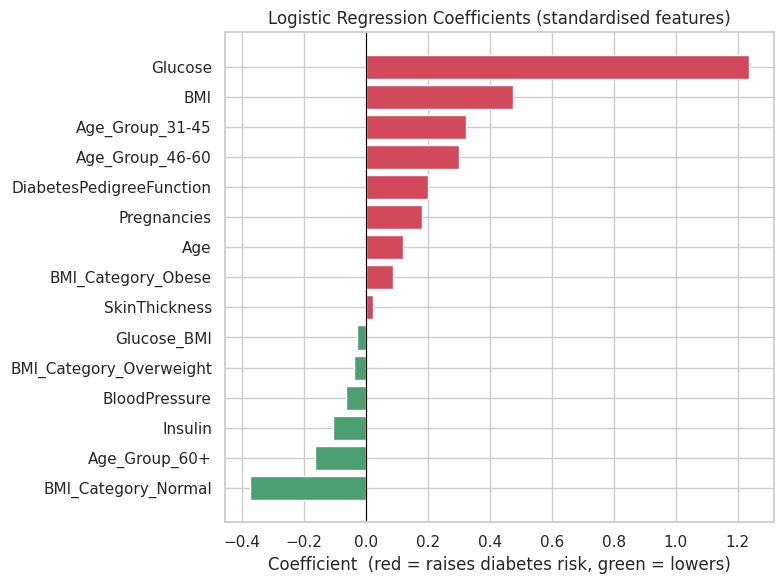

In [23]:
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0],
    "Odds_Ratio": np.exp(model.coef_[0])
}).sort_values("Coefficient", ascending=False).reset_index(drop=True)
print(coef_df.round(3))

plt.figure(figsize=(8, 6))
colors = ["#D1495B" if c > 0 else "#4C9F70" for c in coef_df["Coefficient"][::-1]]
plt.barh(coef_df["Feature"][::-1], coef_df["Coefficient"][::-1], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.title("Logistic Regression Coefficients (standardised features)")
plt.xlabel("Coefficient  (red = raises diabetes risk, green = lowers)")
plt.tight_layout()
plt.show()

Because features are standardised, coefficients are directly comparable (the odds ratio is the change in odds of diabetes per one standard-deviation increase):

- **Glucose is the dominant predictor** (odds ratio ≈ 3.4 per 1 SD), consistent with its 0.47 correlation and with medical knowledge.
- **BMI** (OR ≈ 1.6), **DiabetesPedigreeFunction** (OR ≈ 1.2), **Pregnancies** (OR ≈ 1.2) and **Age** also increase risk.
- Patients with a **normal BMI** have lower risk (OR ≈ 0.69) than the reference (underweight) group.
- BloodPressure, SkinThickness and Insulin contribute little once Glucose and BMI are known. The small negative Insulin coefficient should not be over-interpreted, as ~49 % of its values were imputed and it is correlated with other features.
- The engineered features (BMI category, age group, Glucose×BMI) add little beyond the original variables because Logistic Regression already uses the raw Glucose and BMI. Some of them are partly redundant with each other, so individual engineered coefficients (including the slightly negative Glucose×BMI term) are not reliable on their own.

## 4.4 Improving recall by adjusting the decision threshold

Since missing a diabetic patient is more harmful than a false alarm, we test lower thresholds on the predicted probabilities.

In [24]:
# The default threshold is 0.5. For screening, missing a diabetic patient (FN) is costlier
# than a false alarm (FP), so let's see what a lower threshold does.
rows = []
for t in [0.5, 0.4, 0.3]:
    pred = (y_test_proba >= t).astype(int)
    rows.append({"Threshold": t,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "False Negatives": int(((pred == 0) & (y_test == 1)).sum())})
print(pd.DataFrame(rows).round(3).to_string(index=False))

 Threshold  Accuracy  Precision  Recall    F1  False Negatives
       0.5     0.734      0.644   0.537 0.586               25
       0.4     0.760      0.644   0.704 0.673               16
       0.3     0.766      0.625   0.833 0.714                9


Lowering the threshold from 0.5 to 0.3 raises recall from **54 % to 83 %**, cuts missed diabetic patients from **25 to 9**, and even slightly improves accuracy and F1, at the cost of a small drop in precision (more false alarms). For a **screening tool**, a threshold around 0.3–0.4 is more appropriate than the default. (Note: the threshold was examined on the test set for illustration only. In a real project it should be chosen using a validation set or cross-validation.)

## 4.5 Save the trained model

In [25]:
import joblib
joblib.dump({"preprocessor": preprocessor, "model": model, "columns": list(X.columns)},
            "diabetes_logreg_model.joblib")
print("Model saved to diabetes_logreg_model.joblib")

Model saved to diabetes_logreg_model.joblib


---
## 4.6 Final conclusions

**Summary of results**

| Metric | Training | Testing |
|---|---|---|
| Accuracy | 78.8 % | 73.4 % |
| Precision | 74.7 % | 64.4 % |
| Recall | 59.4 % | 53.7 % |
| F1-Score | 66.2 % | 58.6 % |
| ROC-AUC (test) | n/a | 0.841 |
| 5-fold CV accuracy | 77.0 % ± 2.7 % | |

**Key insights**
1. **Data quality was the biggest preprocessing issue.** Zeros in Glucose, BloodPressure, SkinThickness, Insulin and BMI were hidden missing values. Without converting them to NaN, the model would have learned from false data.
2. **Glucose is the strongest risk factor**, followed by BMI, age, family history (pedigree function) and number of pregnancies. These findings agree with established medical knowledge.
3. **The model generalises reasonably well.** The train/test gap is mild (about 5 pp) and cross-validation (≈ 77 %) confirms stable performance. It beats the 65 % majority-class baseline.
4. **Accuracy hides a recall problem.** At the default threshold the model misses about 46 % of diabetic patients. The high AUC (0.84) shows the model *can* separate the classes, and lowering the threshold to 0.3 lifts recall to about 83 %.
5. **Business/clinical implication:** the model is suited as a **first-level screening aid** that flags patients for confirmatory lab tests (HbA1c, fasting glucose). It must not replace a clinical diagnosis.

**Limitations**
- Small dataset (768 patients) → noisy test estimates; only 54 positive cases in the test set.
- Many imputed values (Insulin, SkinThickness) reduce the information in those features.
- Dataset covers only female patients of Pima Indian heritage aged 21 and older, so results may not generalise to other populations.
- A linear model cannot capture complex non-linear interactions.

**Possible improvements**
- Tune regularisation strength (`C`) with `GridSearchCV`, and try `class_weight="balanced"`.
- Try non-linear models (Random Forest, Gradient Boosting, SVM) and compare using cross-validation.
- Use more advanced imputation (KNN or iterative imputer) and handle outliers.
- Choose the decision threshold on a validation set according to the cost of missed diagnoses.